<a href="https://colab.research.google.com/github/ShikharVeer10/Quantization_and_Pruning/blob/main/Master_Quantization_and_Pruning_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Beyond Downstream Accuracy: Evaluating Representation Fidelity and Deployment Efficiency Under Transformer Compression


**Author:** Shikhar Veer, Jessea Jaison  
**Repository:** https://github.com/ShikharVeer10/Quantization-and-Pruning  
**Base Reference Paper:** Zafrir et al. (2021), *Prune Once for All: Sparse Pre-Trained Language Models* (arXiv:2111.05754)  
**Execution Environment:** Google Colab GPU (Tesla T4) or Local Antigravity IDE



In [ ]:
# ============================================================
# Step 1: Install Dependencies
# ============================================================

import subprocess
import sys
import os

packages = [
    "transformers>=4.40.0",
    "datasets>=2.14.0",
    "accelerate>=0.25.0",
    "evaluate>=0.4.0",
    "scikit-learn>=1.2.0",
    "scipy>=1.10.0",
    "matplotlib>=3.7.0",
    "seaborn>=0.12.0",
    "gradio>=4.0.0",
    "tabulate>=0.9.0",
    "pyyaml>=6.0"
]

print("Installing dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + packages, check=True)
print("✓ All dependencies installed successfully!")

import torch
print(f"PyTorch Version  : {torch.__version__}")
print(f"CUDA Available   : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU Device: {torch.cuda.get_device_name(0)}")



Installing dependencies...
✓ All dependencies installed successfully!
PyTorch Version  : 2.11.0+cu130
CUDA Available   : True
Active GPU Device: Tesla T4


In [ ]:
# ============================================================
# Step 2: Connect Project Workspace
# ============================================================
# Works automatically whether you:
# A) Cloned the repo: git clone https://github.com/ShikharVeer10/Quantization-and-Pruning.git
# B) Uploaded project.zip into Colab files
# C) Running locally in Antigravity IDE

import os
import sys

# If project.zip was dragged into Colab, extract it automatically
if os.path.exists("project.zip") and not os.path.exists("src"):
    print("Extracting project.zip...")
    !unzip -q -o project.zip

# If running on Colab and repository not present, clone it:
if not os.path.exists("src"):
    print("Cloning repository...")
    !git clone https://github.com/ShikharVeer10/Quantization-and-Pruning.git
    if os.path.exists("Quantization-and-Pruning"):
        %cd Quantization-and-Pruning

# Register current working directory into Python path
project_root = os.getcwd()
if project_root not in sys.path:
    sys.path.insert(0, project_root)

print(f"✓ Active directory : {project_root}")
print(f"✓ Project folders  : {[d for d in sorted(os.listdir('.')) if os.path.isdir(d) and not d.startswith('.')]}")



Extracting project.zip...
✓ Active directory : /content
✓ Project folders  : ['Quantization-and-Pruning', 'configs', 'experiments', 'notebooks', 'paper', 'sample_data', 'src', 'tests']


In [ ]:
# ============================================================
# Step 3: Run Automated Mathematical & Unit Tests
# ============================================================
# Verifies pruning sparsity calculation, INT4 numerical bounds,
# triple-loss formulations, and mask preservation under AdamW.

import unittest
from tests.test_pruning import TestPruningModules
from tests.test_quantization import TestQuantizationModules
from tests.test_distillation import TestDistillationModule
from tests.test_evaluation import TestEvaluationModules

suite = unittest.TestSuite()
for test_class in [TestPruningModules, TestQuantizationModules, TestDistillationModule, TestEvaluationModules]:
    tests = unittest.defaultTestLoader.loadTestsFromTestCase(test_class)
    suite.addTests(tests)

runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
assert result.wasSuccessful(), "Unit tests failed! Please check logs above."
print("\n✓ All automated unit and mathematical validation tests PASSED!")



test_global_l1_pruning (tests.test_pruning.TestPruningModules.test_global_l1_pruning) ... ok
test_layer_sparsity_dict (tests.test_pruning.TestPruningModules.test_layer_sparsity_dict) ... ok
test_local_l1_pruning (tests.test_pruning.TestPruningModules.test_local_l1_pruning) ... ok
test_random_pruning (tests.test_pruning.TestPruningModules.test_random_pruning) ... ok
test_structured_l2_pruning (tests.test_pruning.TestPruningModules.test_structured_l2_pruning) ... ok
test_dynamic_int8_quantization (tests.test_quantization.TestQuantizationModules.test_dynamic_int8_quantization) ... ok
test_fp16_conversion (tests.test_quantization.TestQuantizationModules.test_fp16_conversion) ... ok
test_quantization_error_analysis (tests.test_quantization.TestQuantizationModules.test_quantization_error_analysis) ... ok
test_simulated_int4_bounds (tests.test_quantization.TestQuantizationModules.test_simulated_int4_bounds) ... ok
test_mask_preservation_after_optimization (tests.test_distillation.TestDistilla

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

ok

----------------------------------------------------------------------
Ran 14 tests in 9.405s

OK



✓ All automated unit and mathematical validation tests PASSED!


In [ ]:
# ============================================================
# Step 4: Execute Full Research Pipeline (Track A + Track B)
# ============================================================
# Executes:
# 1. Track A: Contextual Language Modeling across 30,522 tokens & 768-dim Embedding Drift
# 2. Layer-wise Sensitivity Analysis (Attention vs FFN across layers 0 to 5)
# 3. Triple-Loss Knowledge Distillation Recovery on degraded sparse model
# 4. Track B: Downstream Task Robustness on SST-2 validation dataset
# 5. Generates 6 publication-quality figures (300 DPI) and exports comparison tables.

from experiments.run_all import run_complete_pipeline

run_complete_pipeline(output_dir="results", device_str="auto")



EXECUTING COMPLETE QUANTIZATION & PRUNING RESEARCH PIPELINE
Target Execution Device: cuda
System environment specifications logged to: results/processed/reproducibility_environment.json

STARTING TRACK A: Contextual Representation & Language Modeling Evaluation
Track A Execution Device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded 400 validation samples from: Curated Balanced Offline Fallback (400 samples)

--- Profiling Dense Fine-Tuned Baseline (SST-2) ---
Baseline -> Accuracy: 100.0% | F1: 100.0% | Latency: 5.18 ms | Size: 255.45 MB

Evaluating Track B Pruning Method: Global L1
  [Global L1 15% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.06 ms
  [Global L1 30% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.09 ms
  [Global L1 45% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.21 ms
  [Global L1 60% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 6.65 ms
  [Global L1 75% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.17 ms

Evaluating Track B Pruning Method: Local L1
  [Local L1 15% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 4.98 ms
  [Local L1 30% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.3 ms
  [Local L1 45% FP32] Acc: 100.0% | F1: 100.0% | Consistency: 100.0% | Lat: 5.01 ms
  [Local L1 60% F

In [ ]:
# ============================================================
# Step 5: Master Comparison Tables & Decoupling Analysis
# ============================================================

import pandas as pd
from IPython.display import display, Markdown

print("=== TRACK A: CONTEXTUAL REPRESENTATION & MLM RESULTS ===")
df_a = pd.read_csv("results/raw/track_a_results.csv")
display(df_a)

print("\n=== TRACK B: DOWNSTREAM CLASSIFICATION (SST-2) RESULTS ===")
df_b = pd.read_csv("results/raw/track_b_results.csv")
display(df_b)

print("\n=== EMPIRICAL DECOUPLING: REPRESENTATION COLLAPSE VS DOWNSTREAM ROBUSTNESS ===")
with open("results/tables/representation_vs_downstream_decoupling.md", "r", encoding="utf-8") as f:
    decoupling_md = f.read()
display(Markdown(decoupling_md))



=== TRACK A: CONTEXTUAL REPRESENTATION & MLM RESULTS ===


,regime,pruning_method,sparsity_pct,quantization,size_mb,size_reduction_pct,top1_accuracy,top5_accuracy,mean_ce_loss,pseudo_perplexity,mean_cosine_similarity,spearman_rank_correlation,median_latency_ms,p95_latency_ms,speedup
0,Dense Baseline,NaN,0.00,FP32,255.57,0.0,50.00,75.00,2.5059,12.25,1.0000,1.0000,5.68,12.91,1.00
1,Local L1 15% (FP32),Local L1,15.00,FP32,255.57,0.0,50.00,75.00,2.5731,13.11,0.9917,0.9842,6.07,8.39,0.94
2,Local L1 15% (INT8),Local L1,15.00,Dynamic INT8,154.77,39.4,50.00,79.17,3.0017,20.12,0.9409,0.5159,70.76,81.34,0.08
3,Local L1 30% (FP32),Local L1,30.00,FP32,255.57,0.0,33.33,70.83,3.1911,24.32,0.9641,0.9711,6.01,7.24,0.95
4,Local L1 30% (INT8),Local L1,30.00,Dynamic INT8,154.77,39.4,29.17,54.17,3.9555,52.22,0.9285,0.8534,71.22,80.10,0.08
5,Local L1 45% (FP32),Local L1,45.00,FP32,255.57,0.0,8.33,8.33,6.5864,725.17,0.8431,0.8192,7.15,8.69,0.79
6,Local L1 45% (INT8),Local L1,45.00,Dynamic INT8,154.77,39.4,0.00,12.50,7.3485,1553.86,0.8276,0.7505,69.78,80.96,0.08
7,Local L1 60% (FP32),Local L1,60.00,FP32,255.57,0.0,0.00,0.00,9.8434,18833.64,0.5092,0.6174,6.17,9.01,0.92
8,Local L1 60% (INT8),Local L1,60.00,Dynamic INT8,154.77,39.4,0.00,0.00,9.9704,21384.04,0.4819,0.6152,71.00,82.19,0.08
9,Local L1 75% (FP32),Local L1,75.00,FP32,255.57,0.0,0.00,0.00,9.9240,20414.49,0.4277,0.6553,5.78,6.46,0.98



=== TRACK B: DOWNSTREAM CLASSIFICATION (SST-2) RESULTS ===


,regime,pruning_method,sparsity_pct,quantization,size_mb,size_reduction_pct,accuracy,precision,recall,f1,prediction_consistency,median_latency_ms,p95_latency_ms,speedup
0,Dense Baseline,NaN,0.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,5.18,5.58,1.00
1,Global L1 15% (FP32),Global L1,15.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,5.06,5.74,1.02
2,Global L1 15% (INT8),Global L1,15.0,Dynamic INT8,132.29,48.2,100.0,100.0,100.0,100.0,100.0,52.44,72.58,0.10
3,Global L1 30% (FP32),Global L1,30.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,5.09,7.93,1.02
4,Global L1 30% (INT8),Global L1,30.0,Dynamic INT8,132.29,48.2,100.0,100.0,100.0,100.0,100.0,64.31,76.39,0.08
5,Global L1 45% (FP32),Global L1,45.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,5.21,5.78,0.99
6,Global L1 45% (INT8),Global L1,45.0,Dynamic INT8,132.29,48.2,100.0,100.0,100.0,100.0,100.0,45.95,52.96,0.11
7,Global L1 60% (FP32),Global L1,60.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,6.65,8.07,0.78
8,Global L1 60% (INT8),Global L1,60.0,Dynamic INT8,132.29,48.2,100.0,100.0,100.0,100.0,100.0,47.15,56.94,0.11
9,Global L1 75% (FP32),Global L1,75.0,FP32,255.45,0.0,100.0,100.0,100.0,100.0,100.0,5.17,5.86,1.00



=== EMPIRICAL DECOUPLING: REPRESENTATION COLLAPSE VS DOWNSTREAM ROBUSTNESS ===


# Empirical Decoupling: Contextual Representation Collapse vs Downstream Task Robustness

| pruning_method   |   sparsity_pct |   Track_A_Top5_Acc_% |   Track_A_Embedding_CosSim |   Track_B_SST2_Acc_% |   Track_B_Consistency_% |
|:-----------------|---------------:|---------------------:|---------------------------:|---------------------:|------------------------:|
| None             |              0 |                75    |                     1      |                  100 |                     100 |
| Local L1         |             15 |                75    |                     0.9917 |                  100 |                     100 |
| Local L1         |             30 |                70.83 |                     0.9641 |                  100 |                     100 |
| Local L1         |             45 |                 8.33 |                     0.8431 |                  100 |                     100 |
| Local L1         |             60 |                 0    |                     0.5092 |                  100 |                     100 |
| Local L1         |             75 |                 0    |                     0.4277 |                  100 |                     100 |
| Global L1        |             15 |                75    |                     0.9897 |                  100 |                     100 |
| Global L1        |             30 |                79.17 |                     0.9524 |                  100 |                     100 |
| Global L1        |             45 |                20.83 |                     0.7921 |                  100 |                     100 |
| Global L1        |             60 |                 0    |                     0.5334 |                  100 |                     100 |
| Global L1        |             75 |                 0    |                     0.4548 |                  100 |                     100 |


results/figures/fig1_context_accuracy_vs_sparsity.png


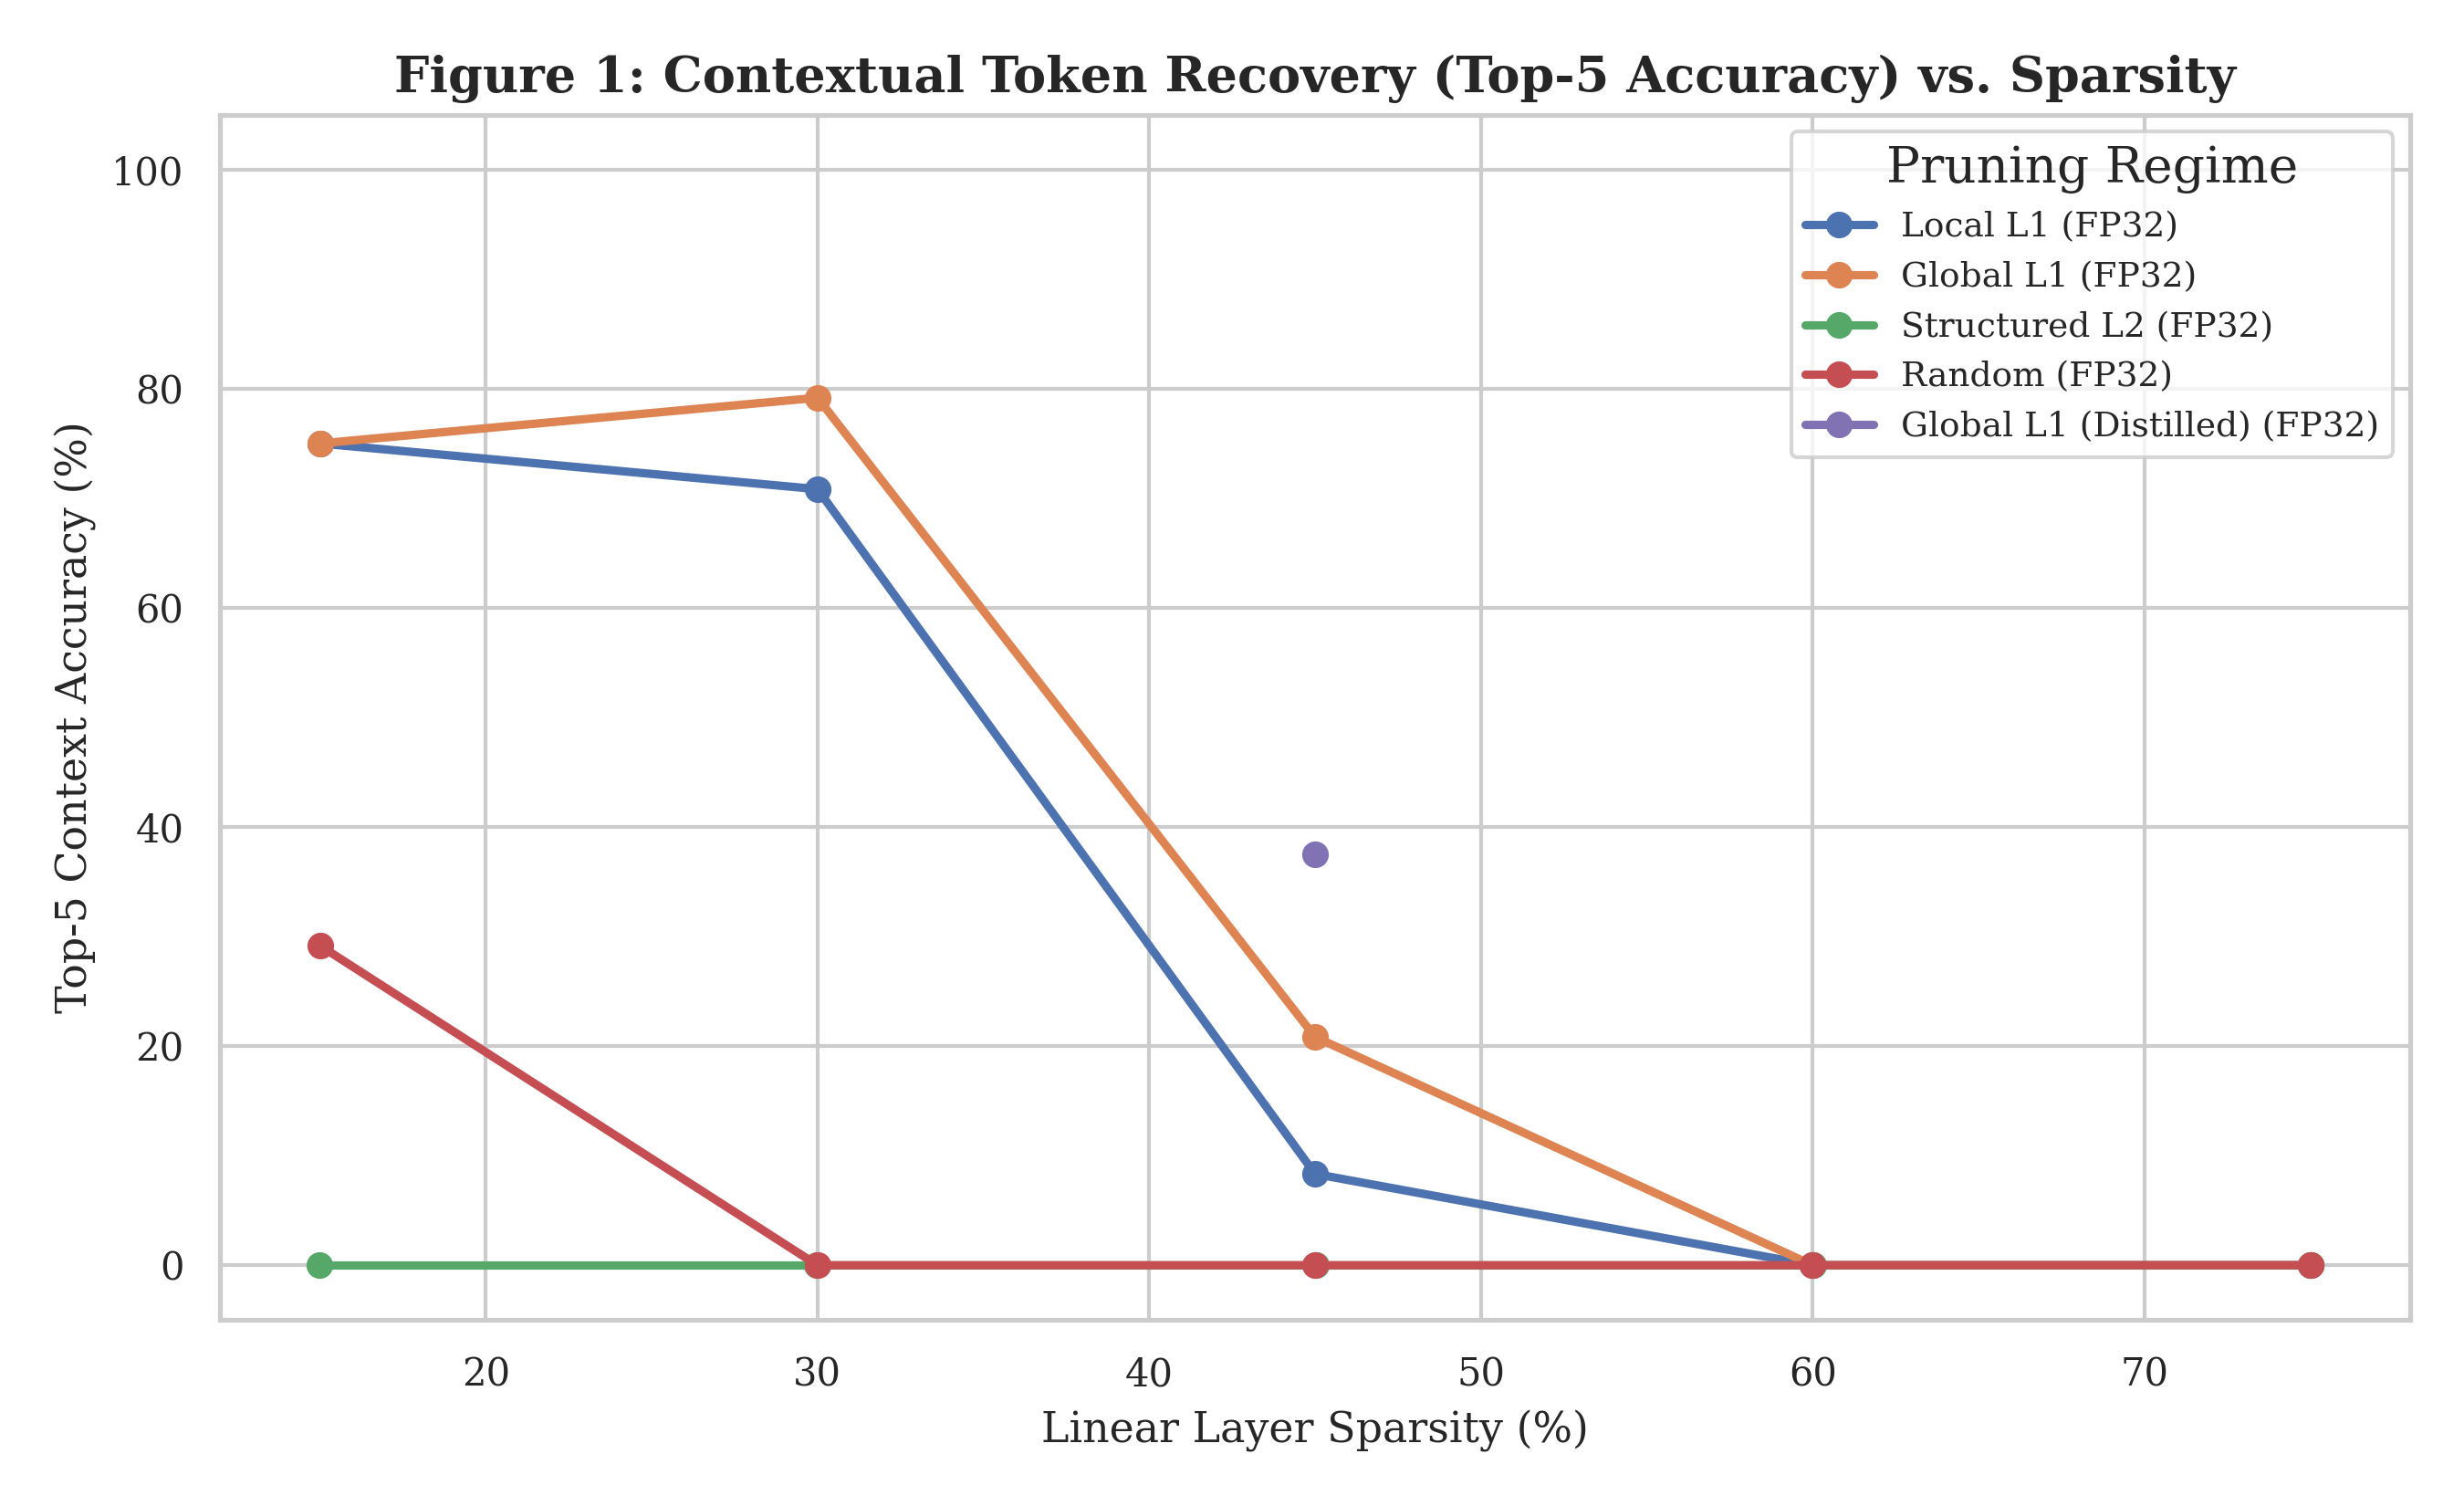


results/figures/fig2_embedding_drift.png


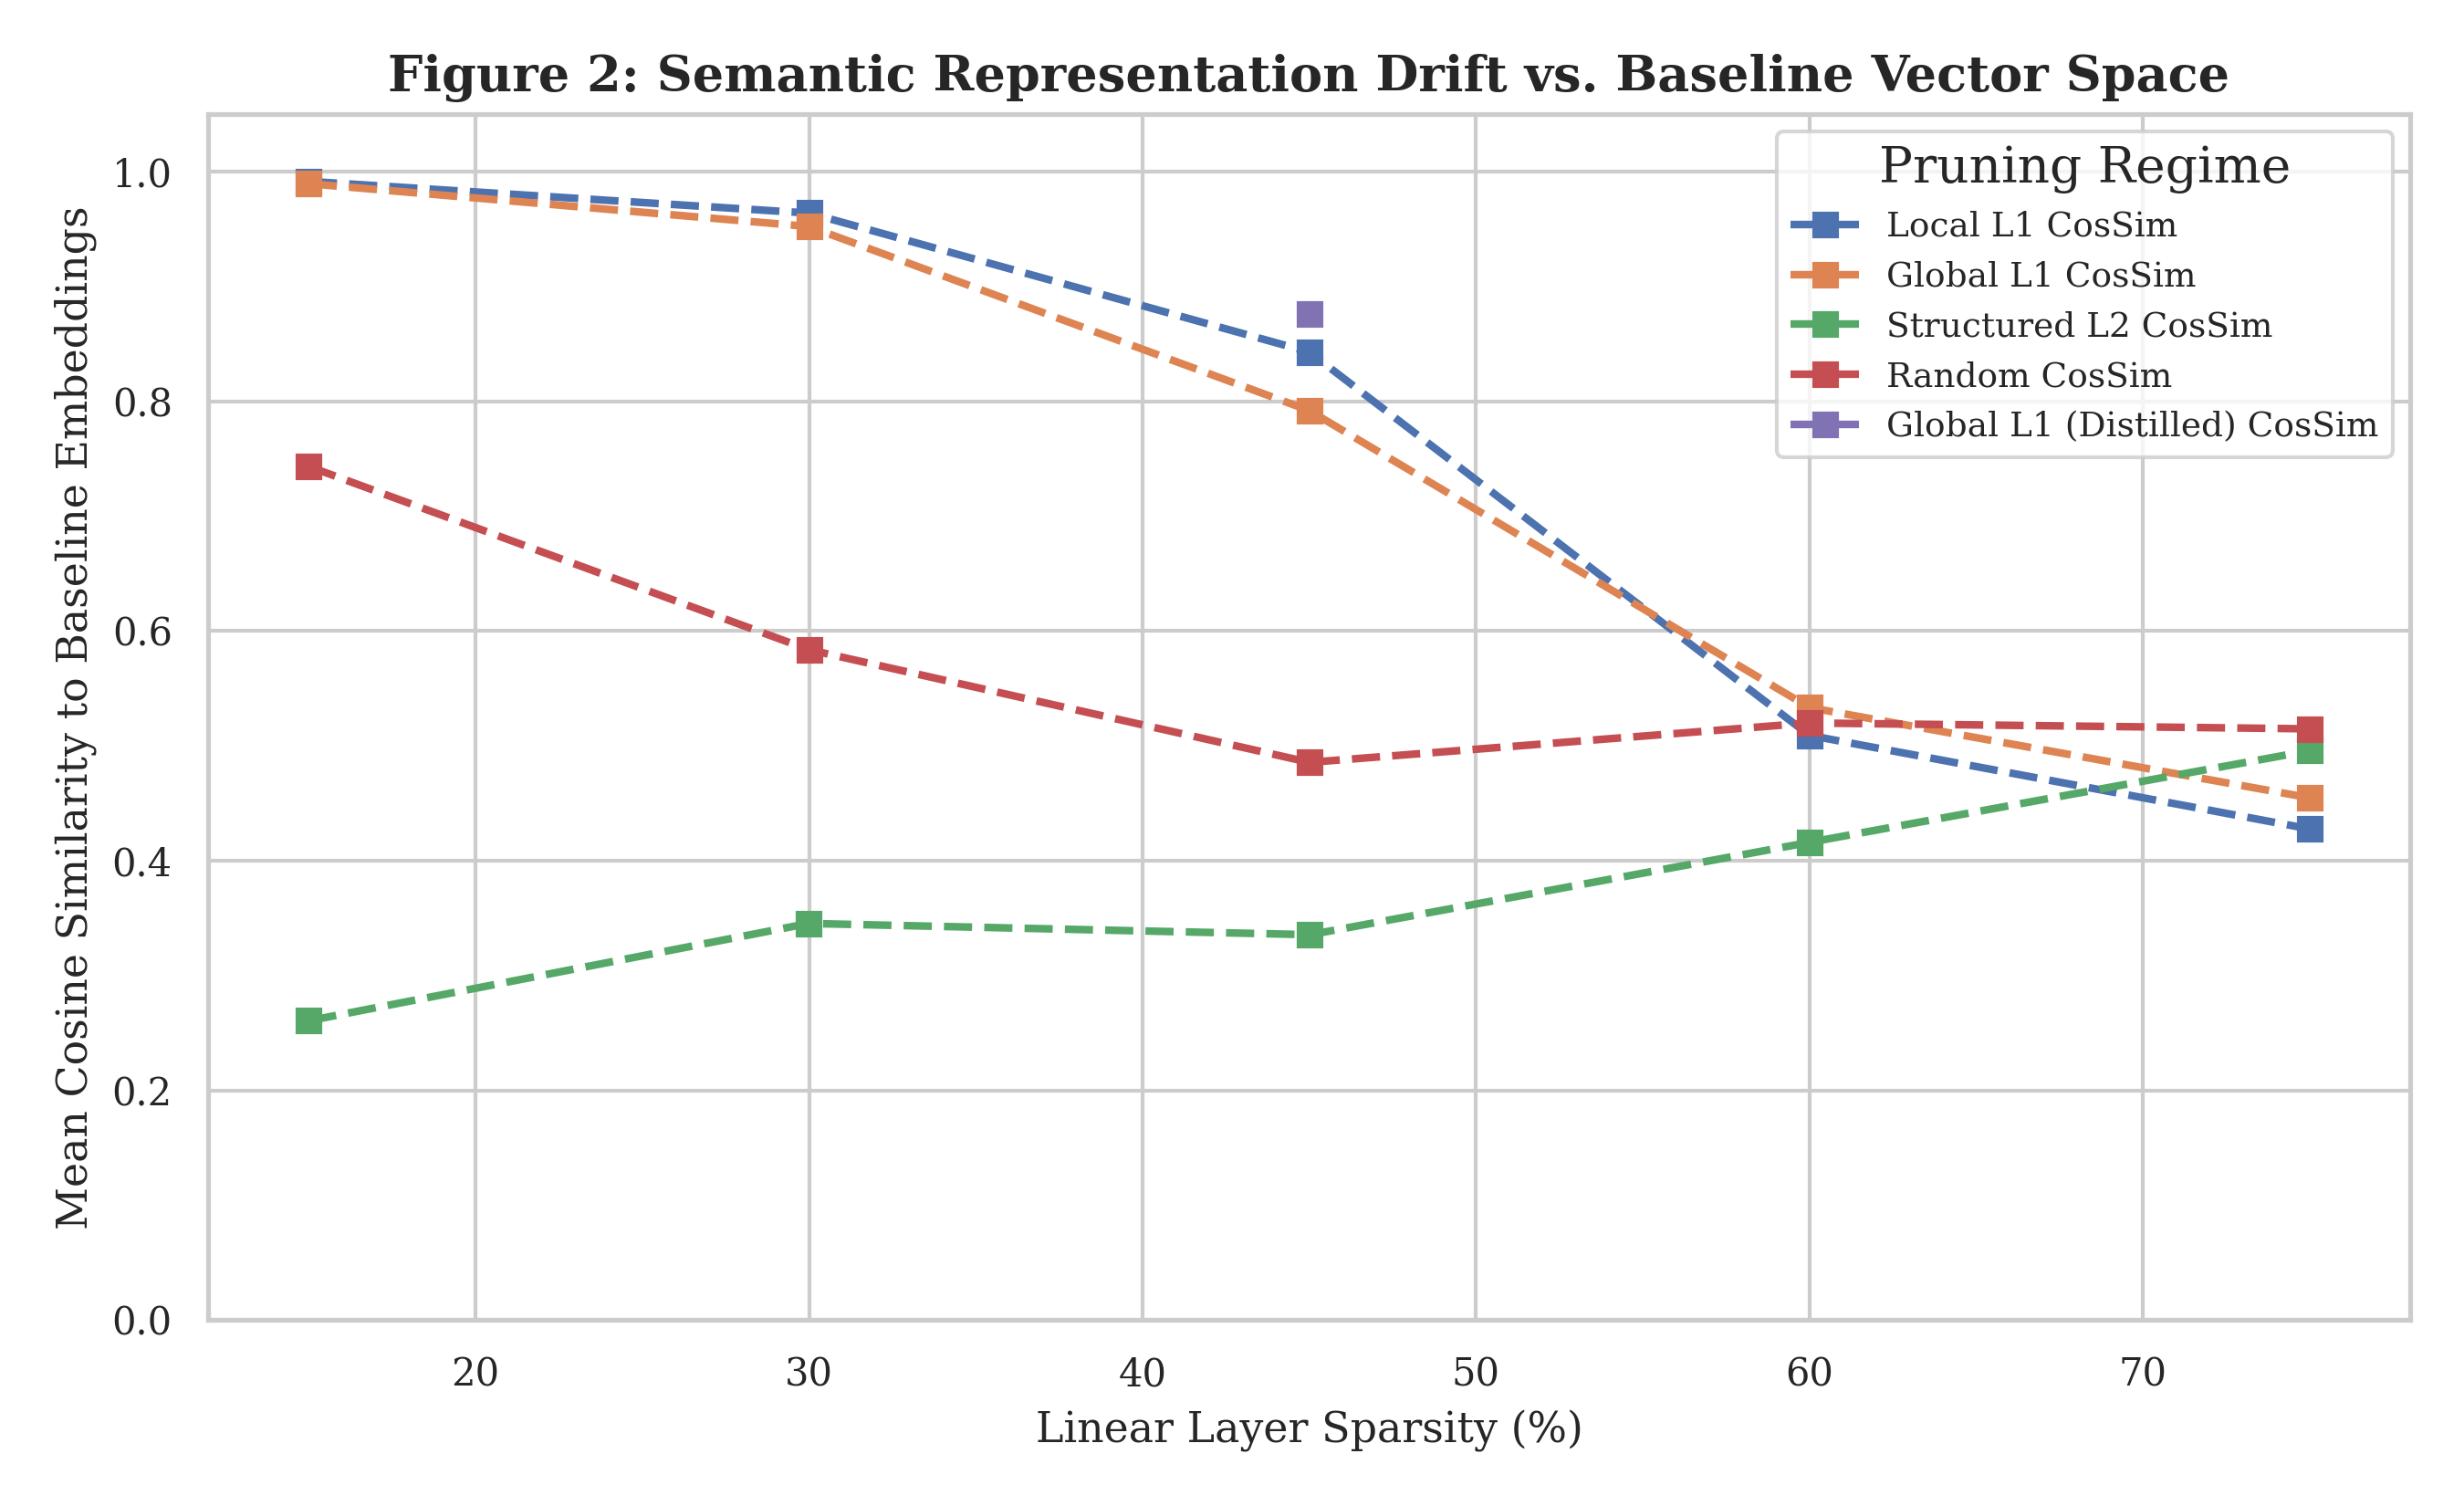


results/figures/fig3_pareto_frontier.png


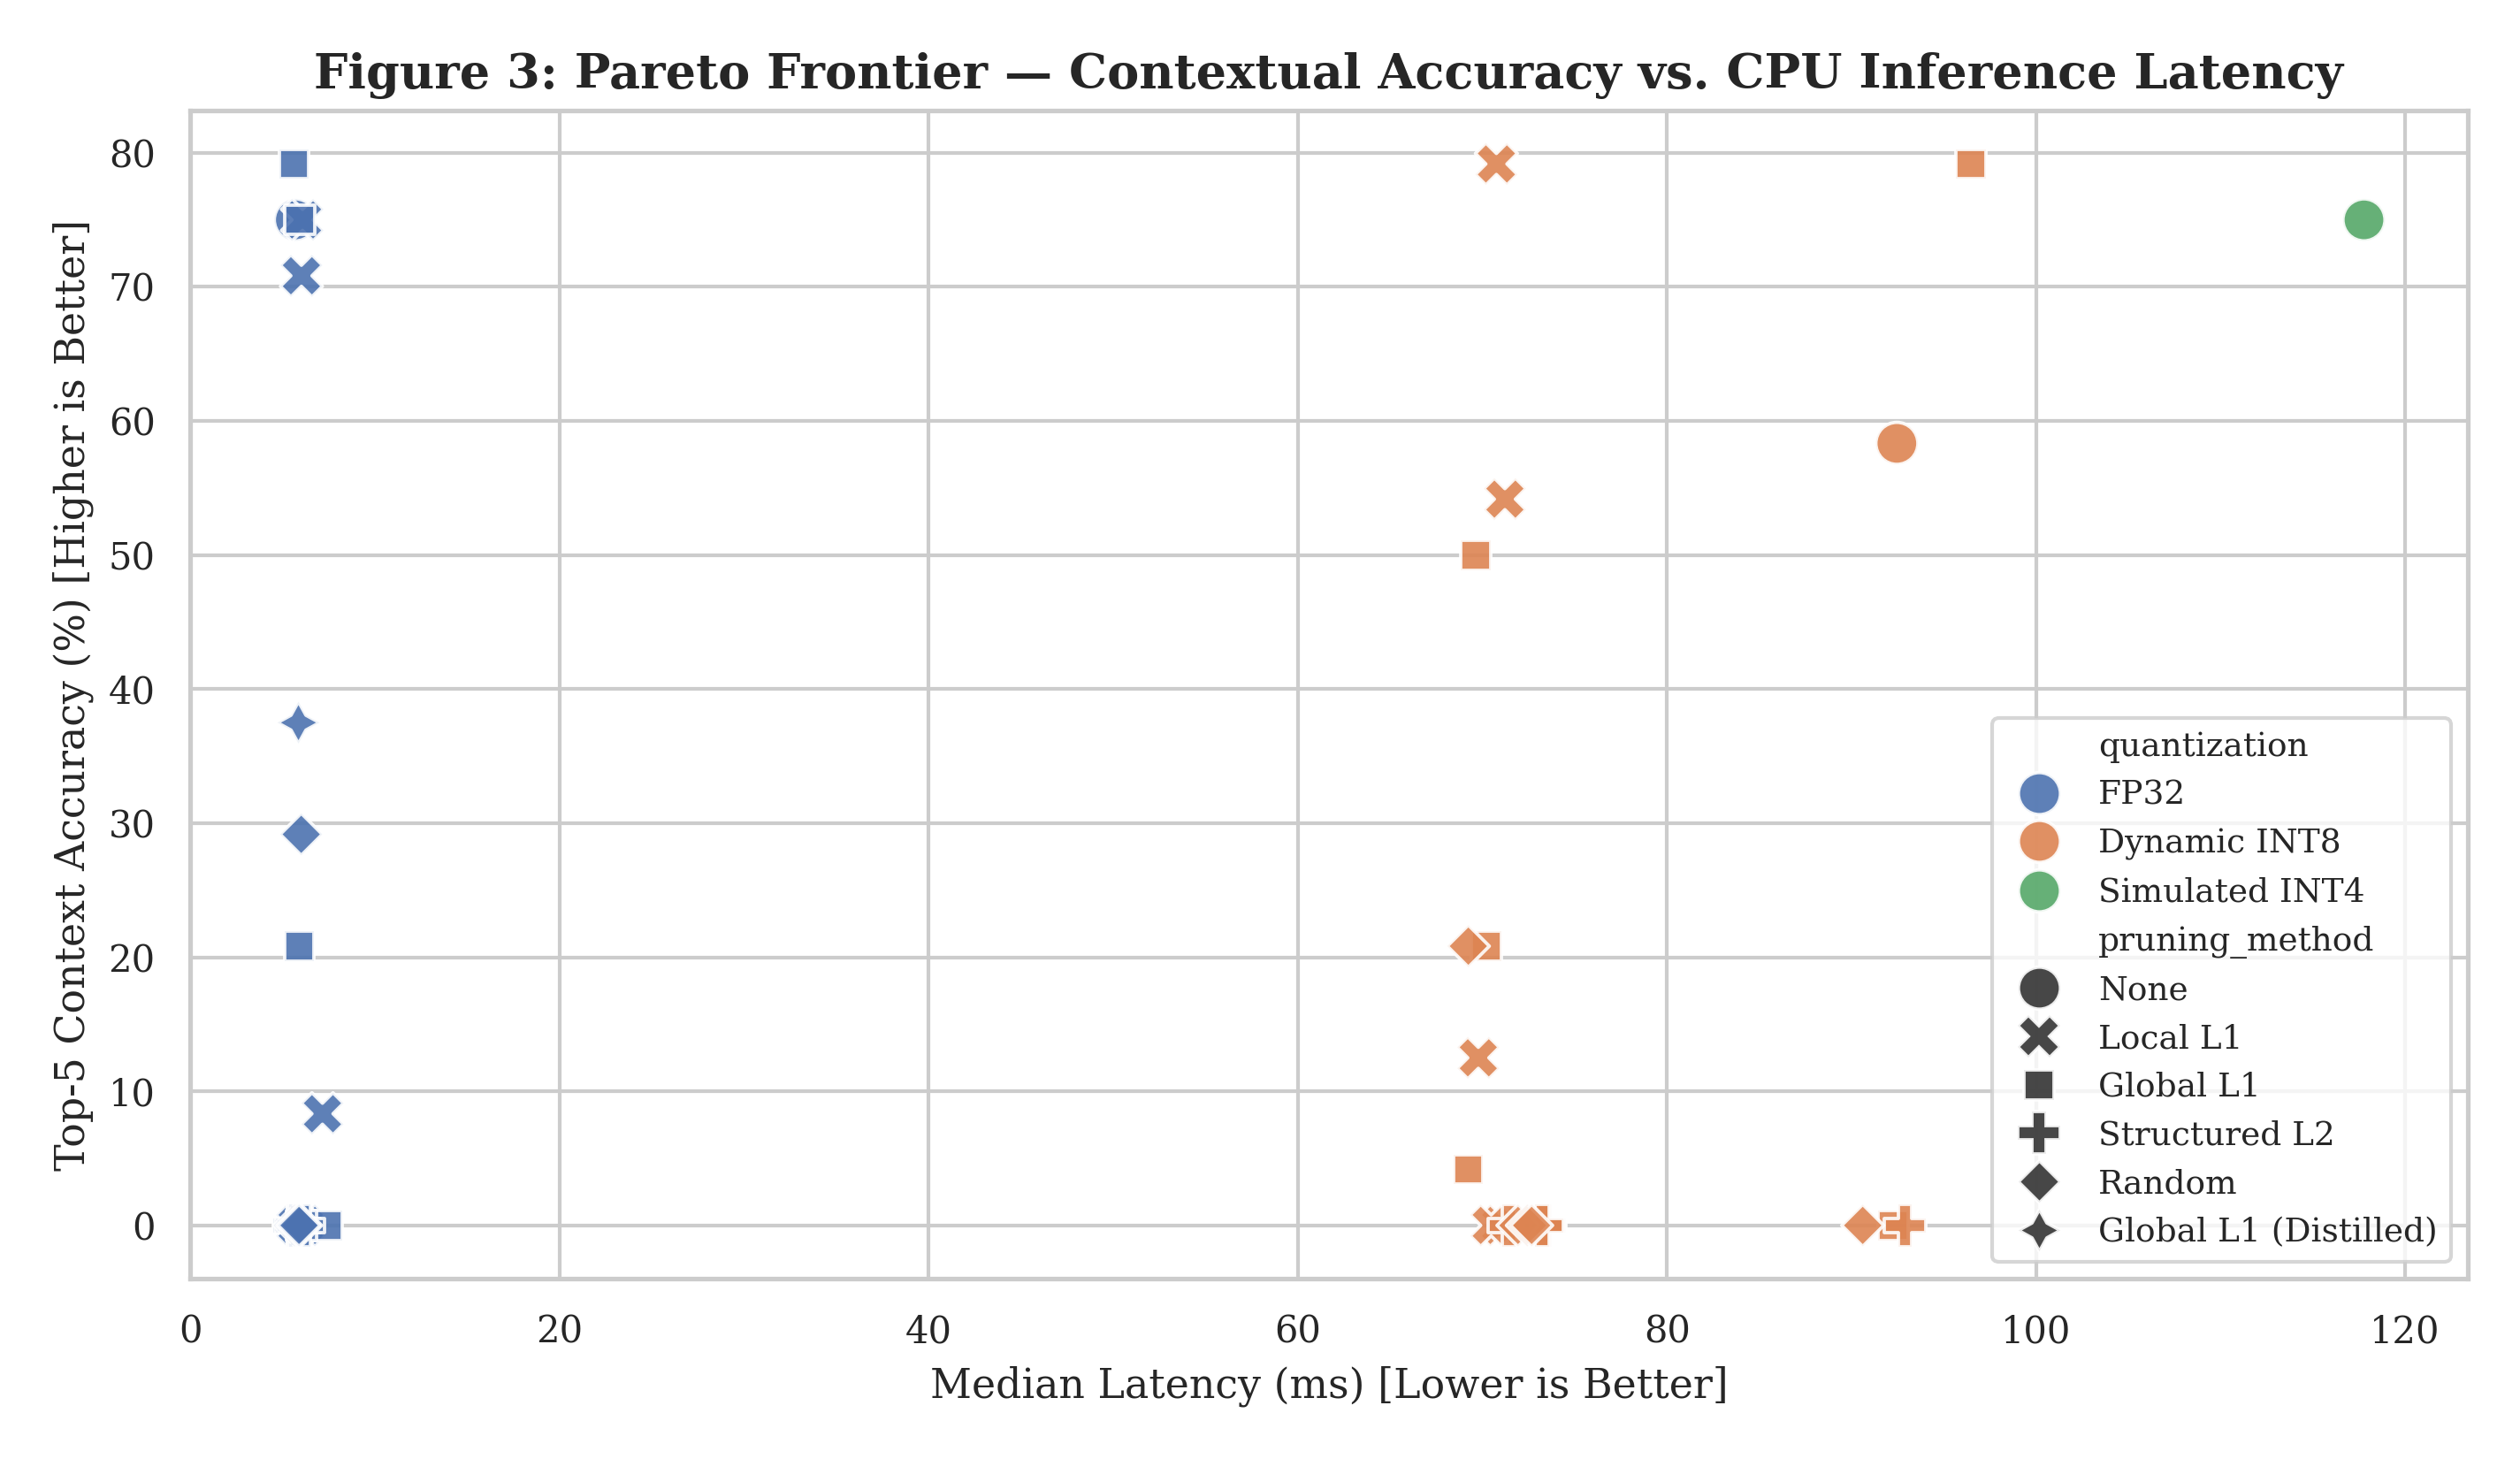


results/figures/fig4_layer_sensitivity_heatmap.png


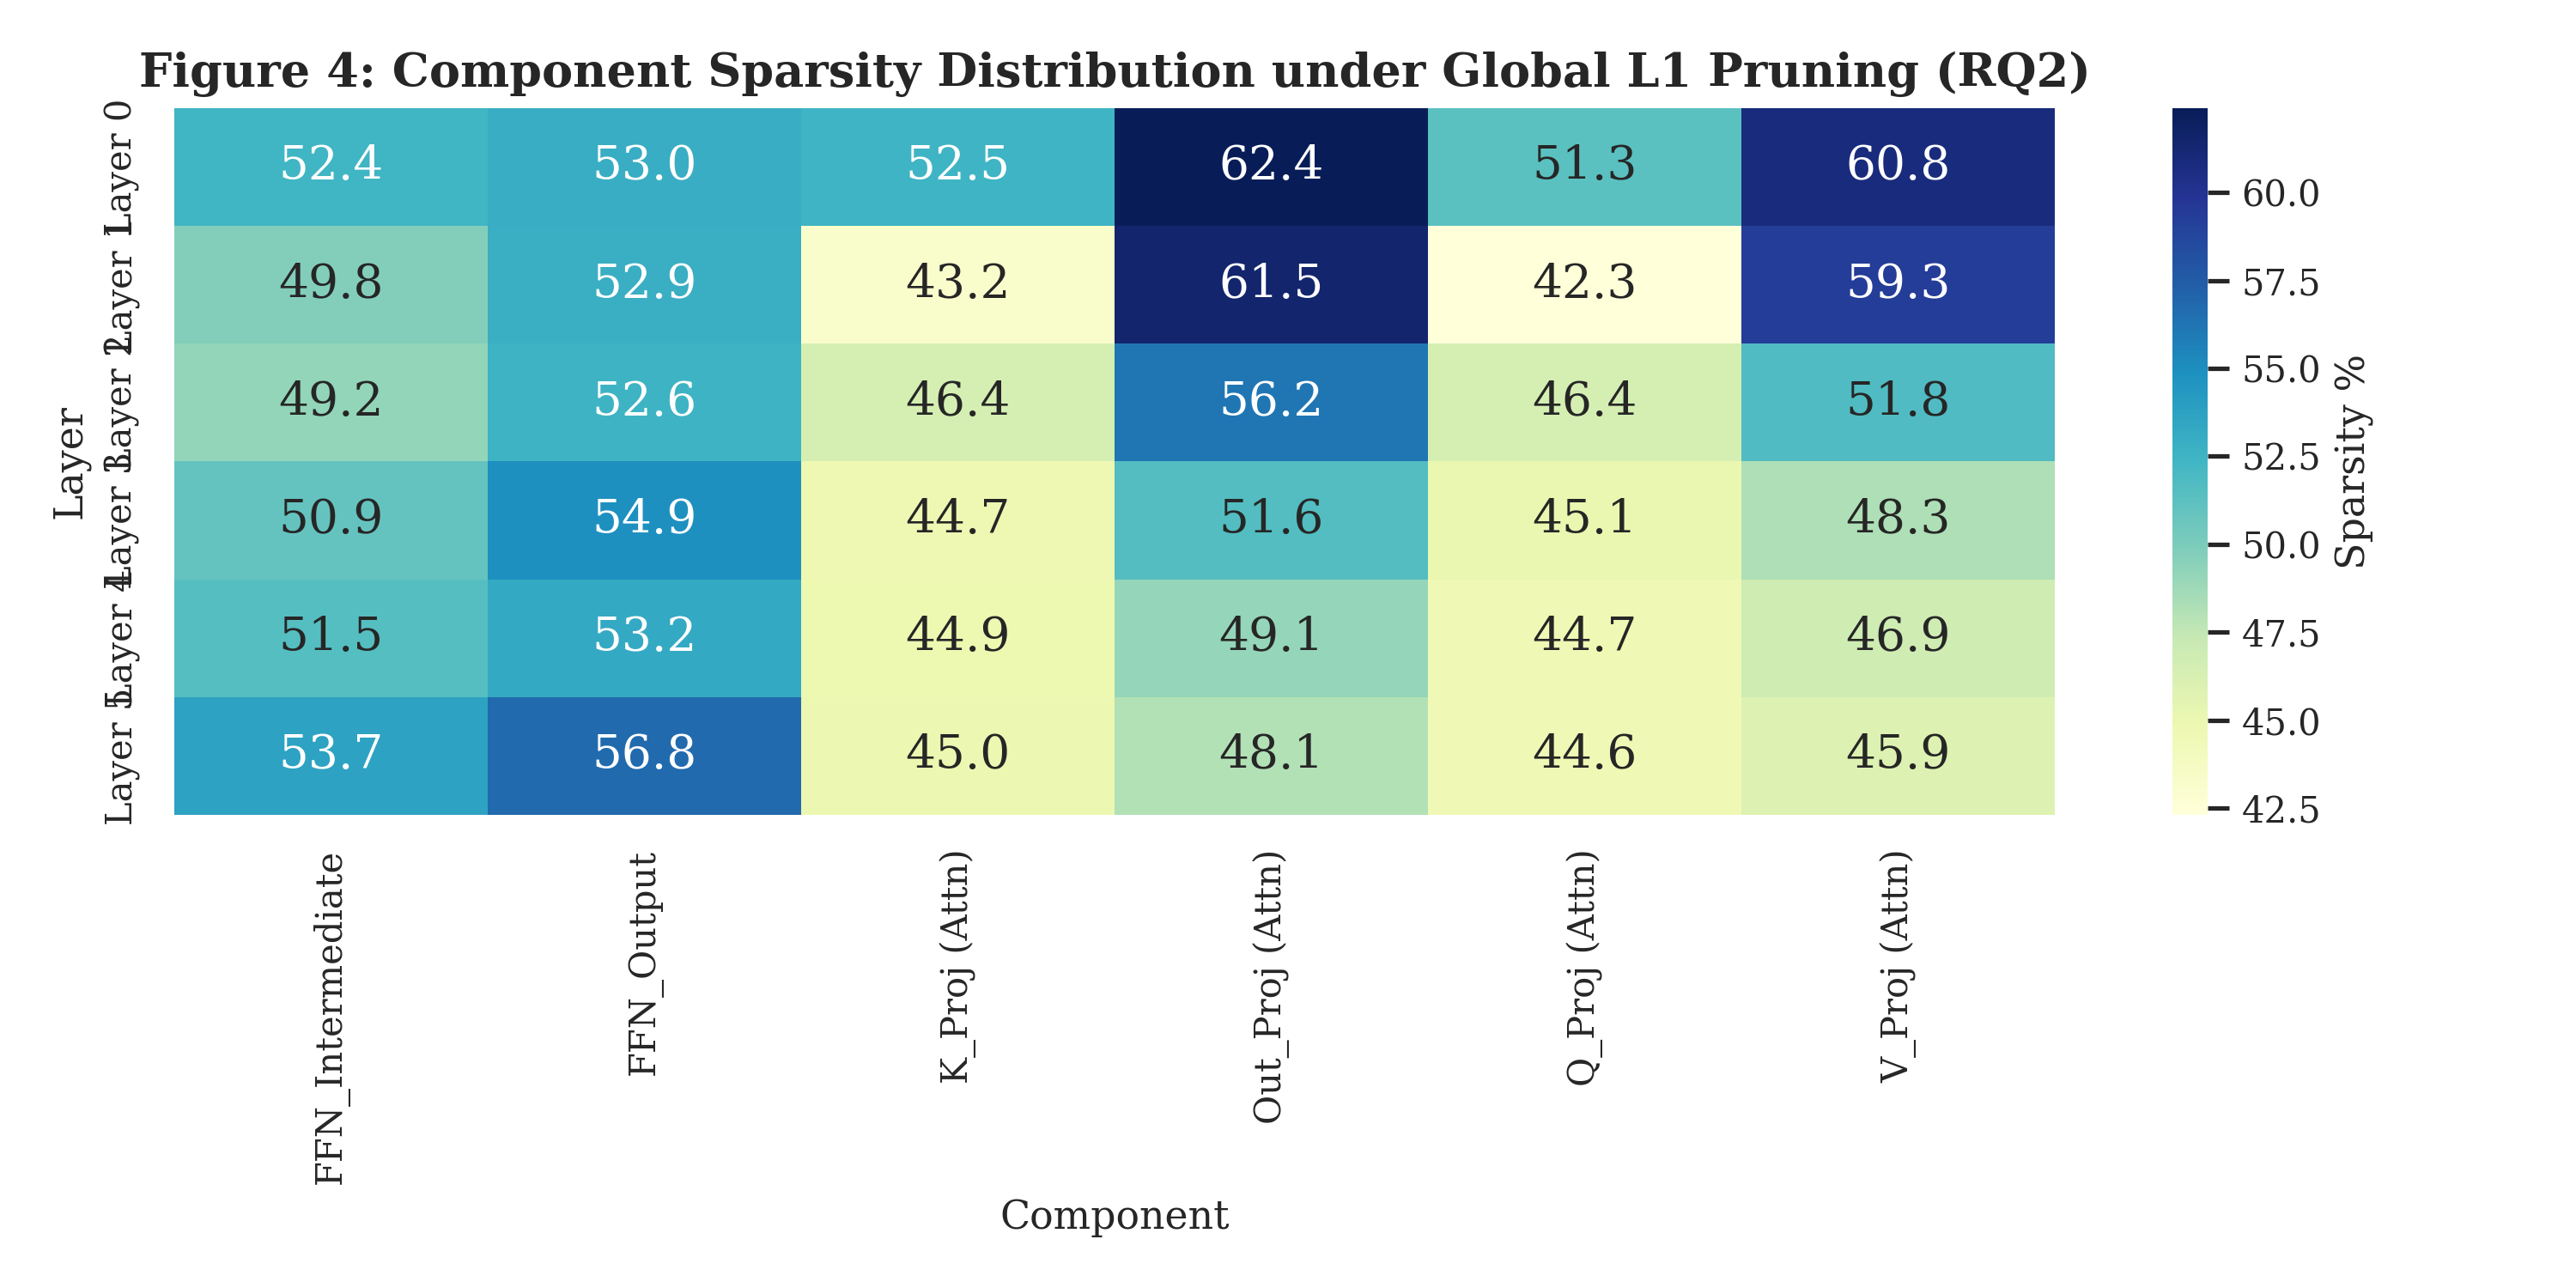


results/figures/fig5_distillation_recovery.png


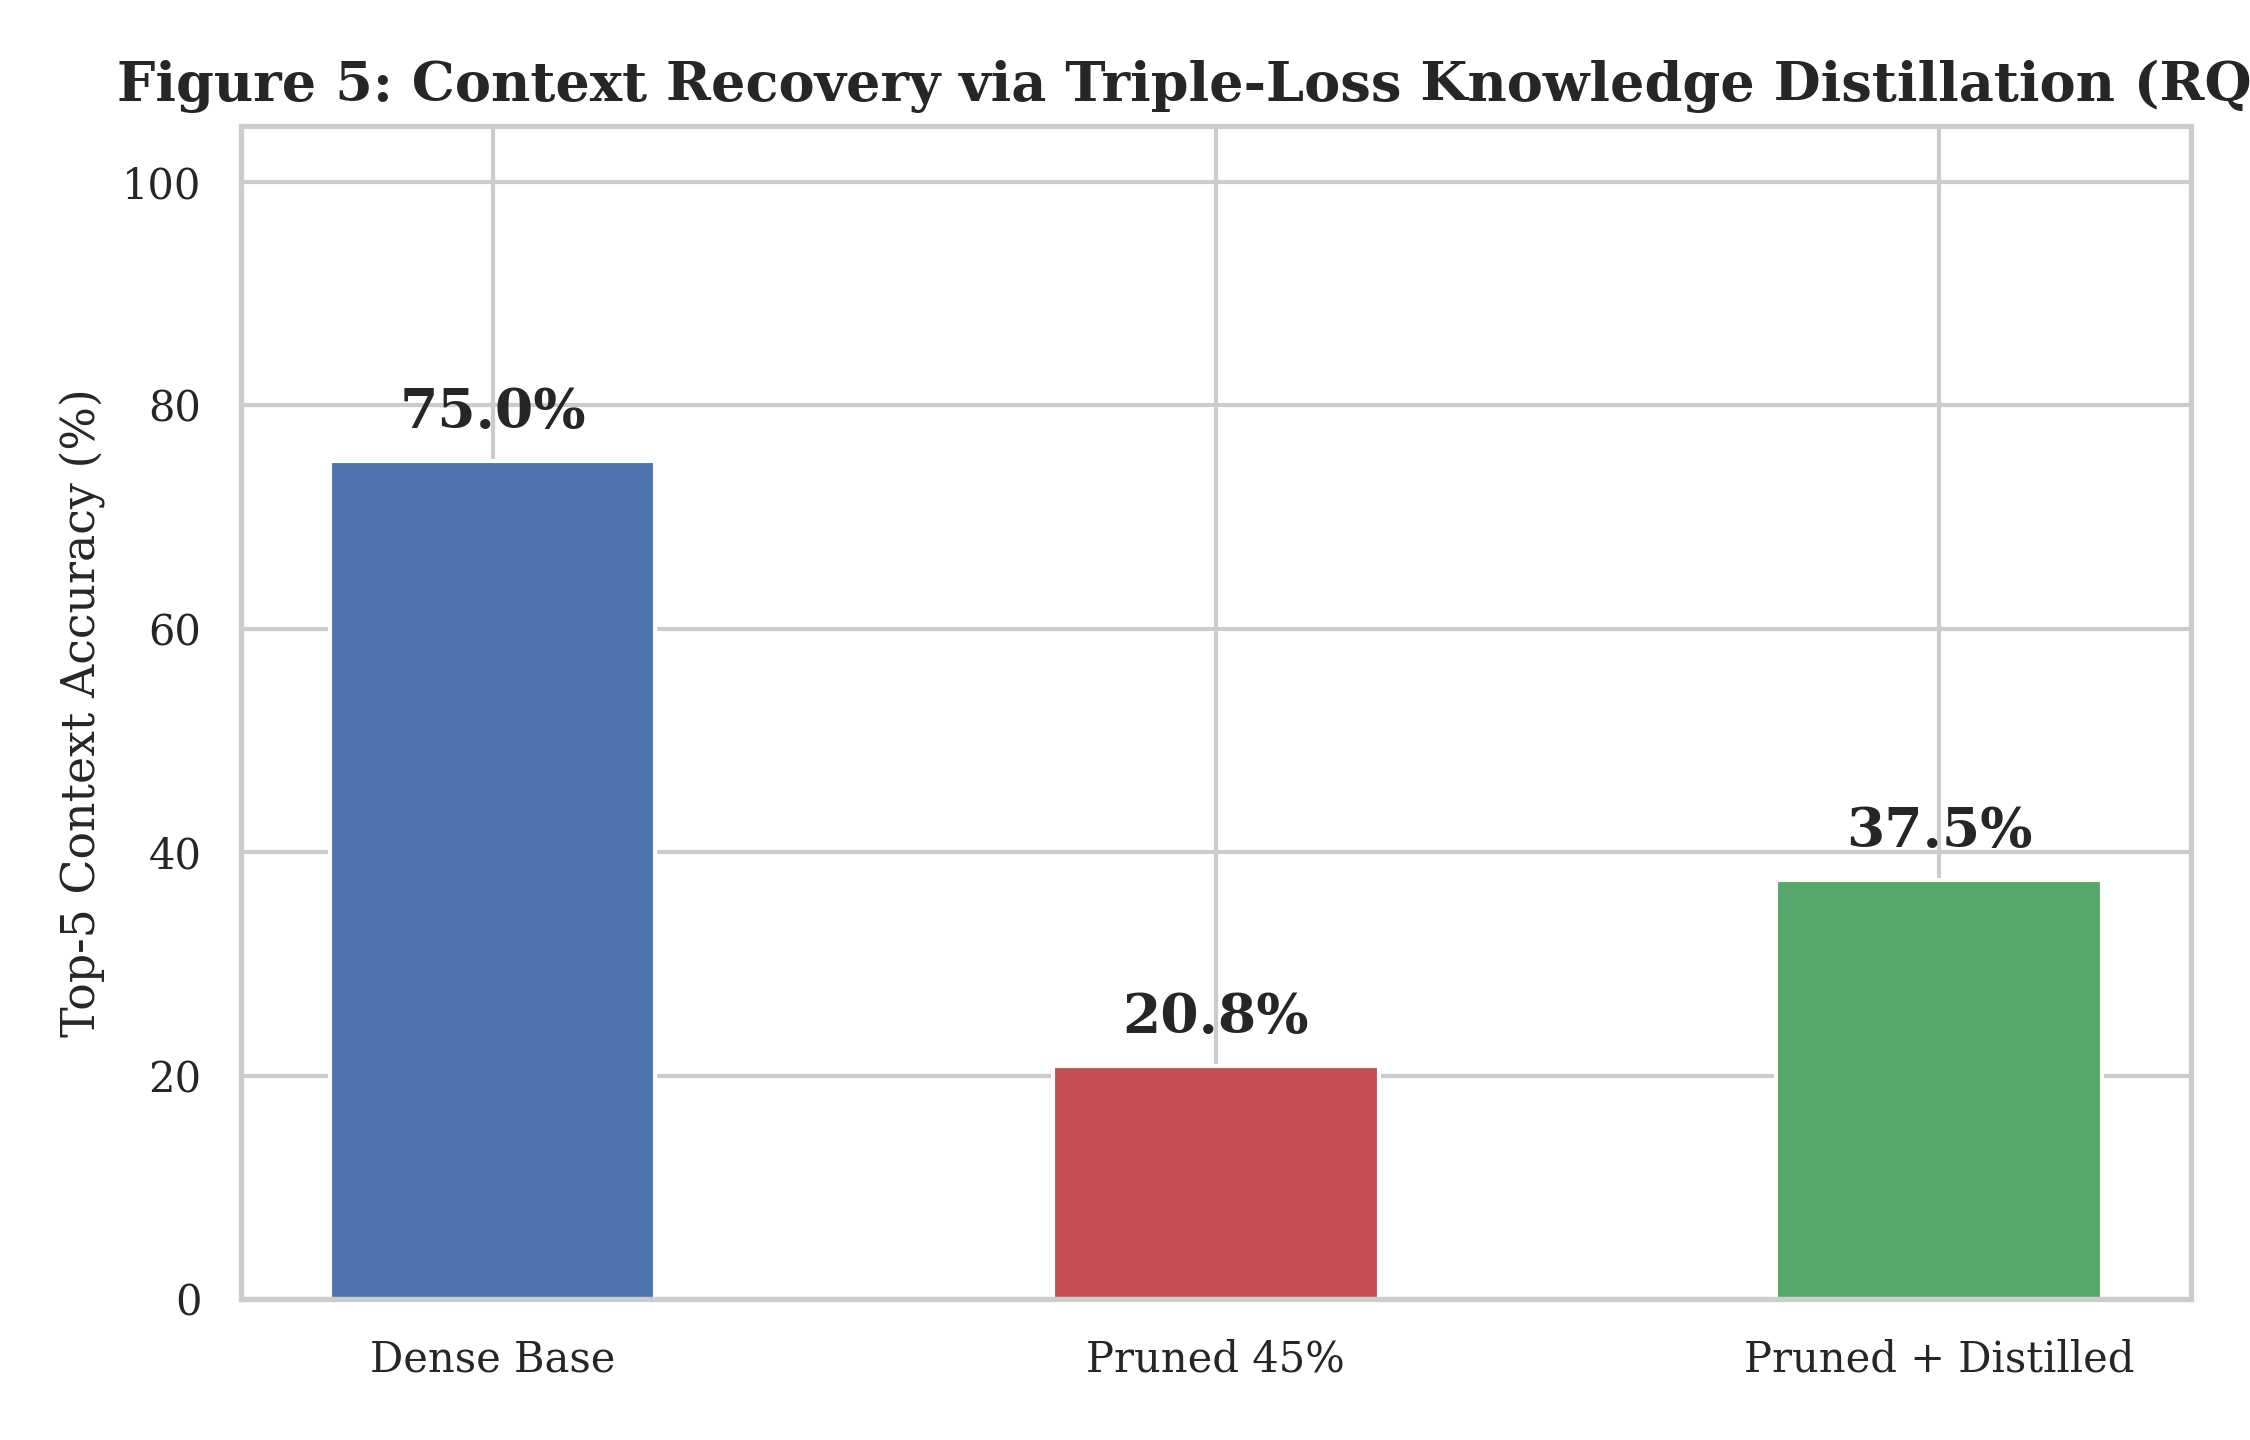


results/figures/fig6_decoupling_track_a_vs_track_b.png


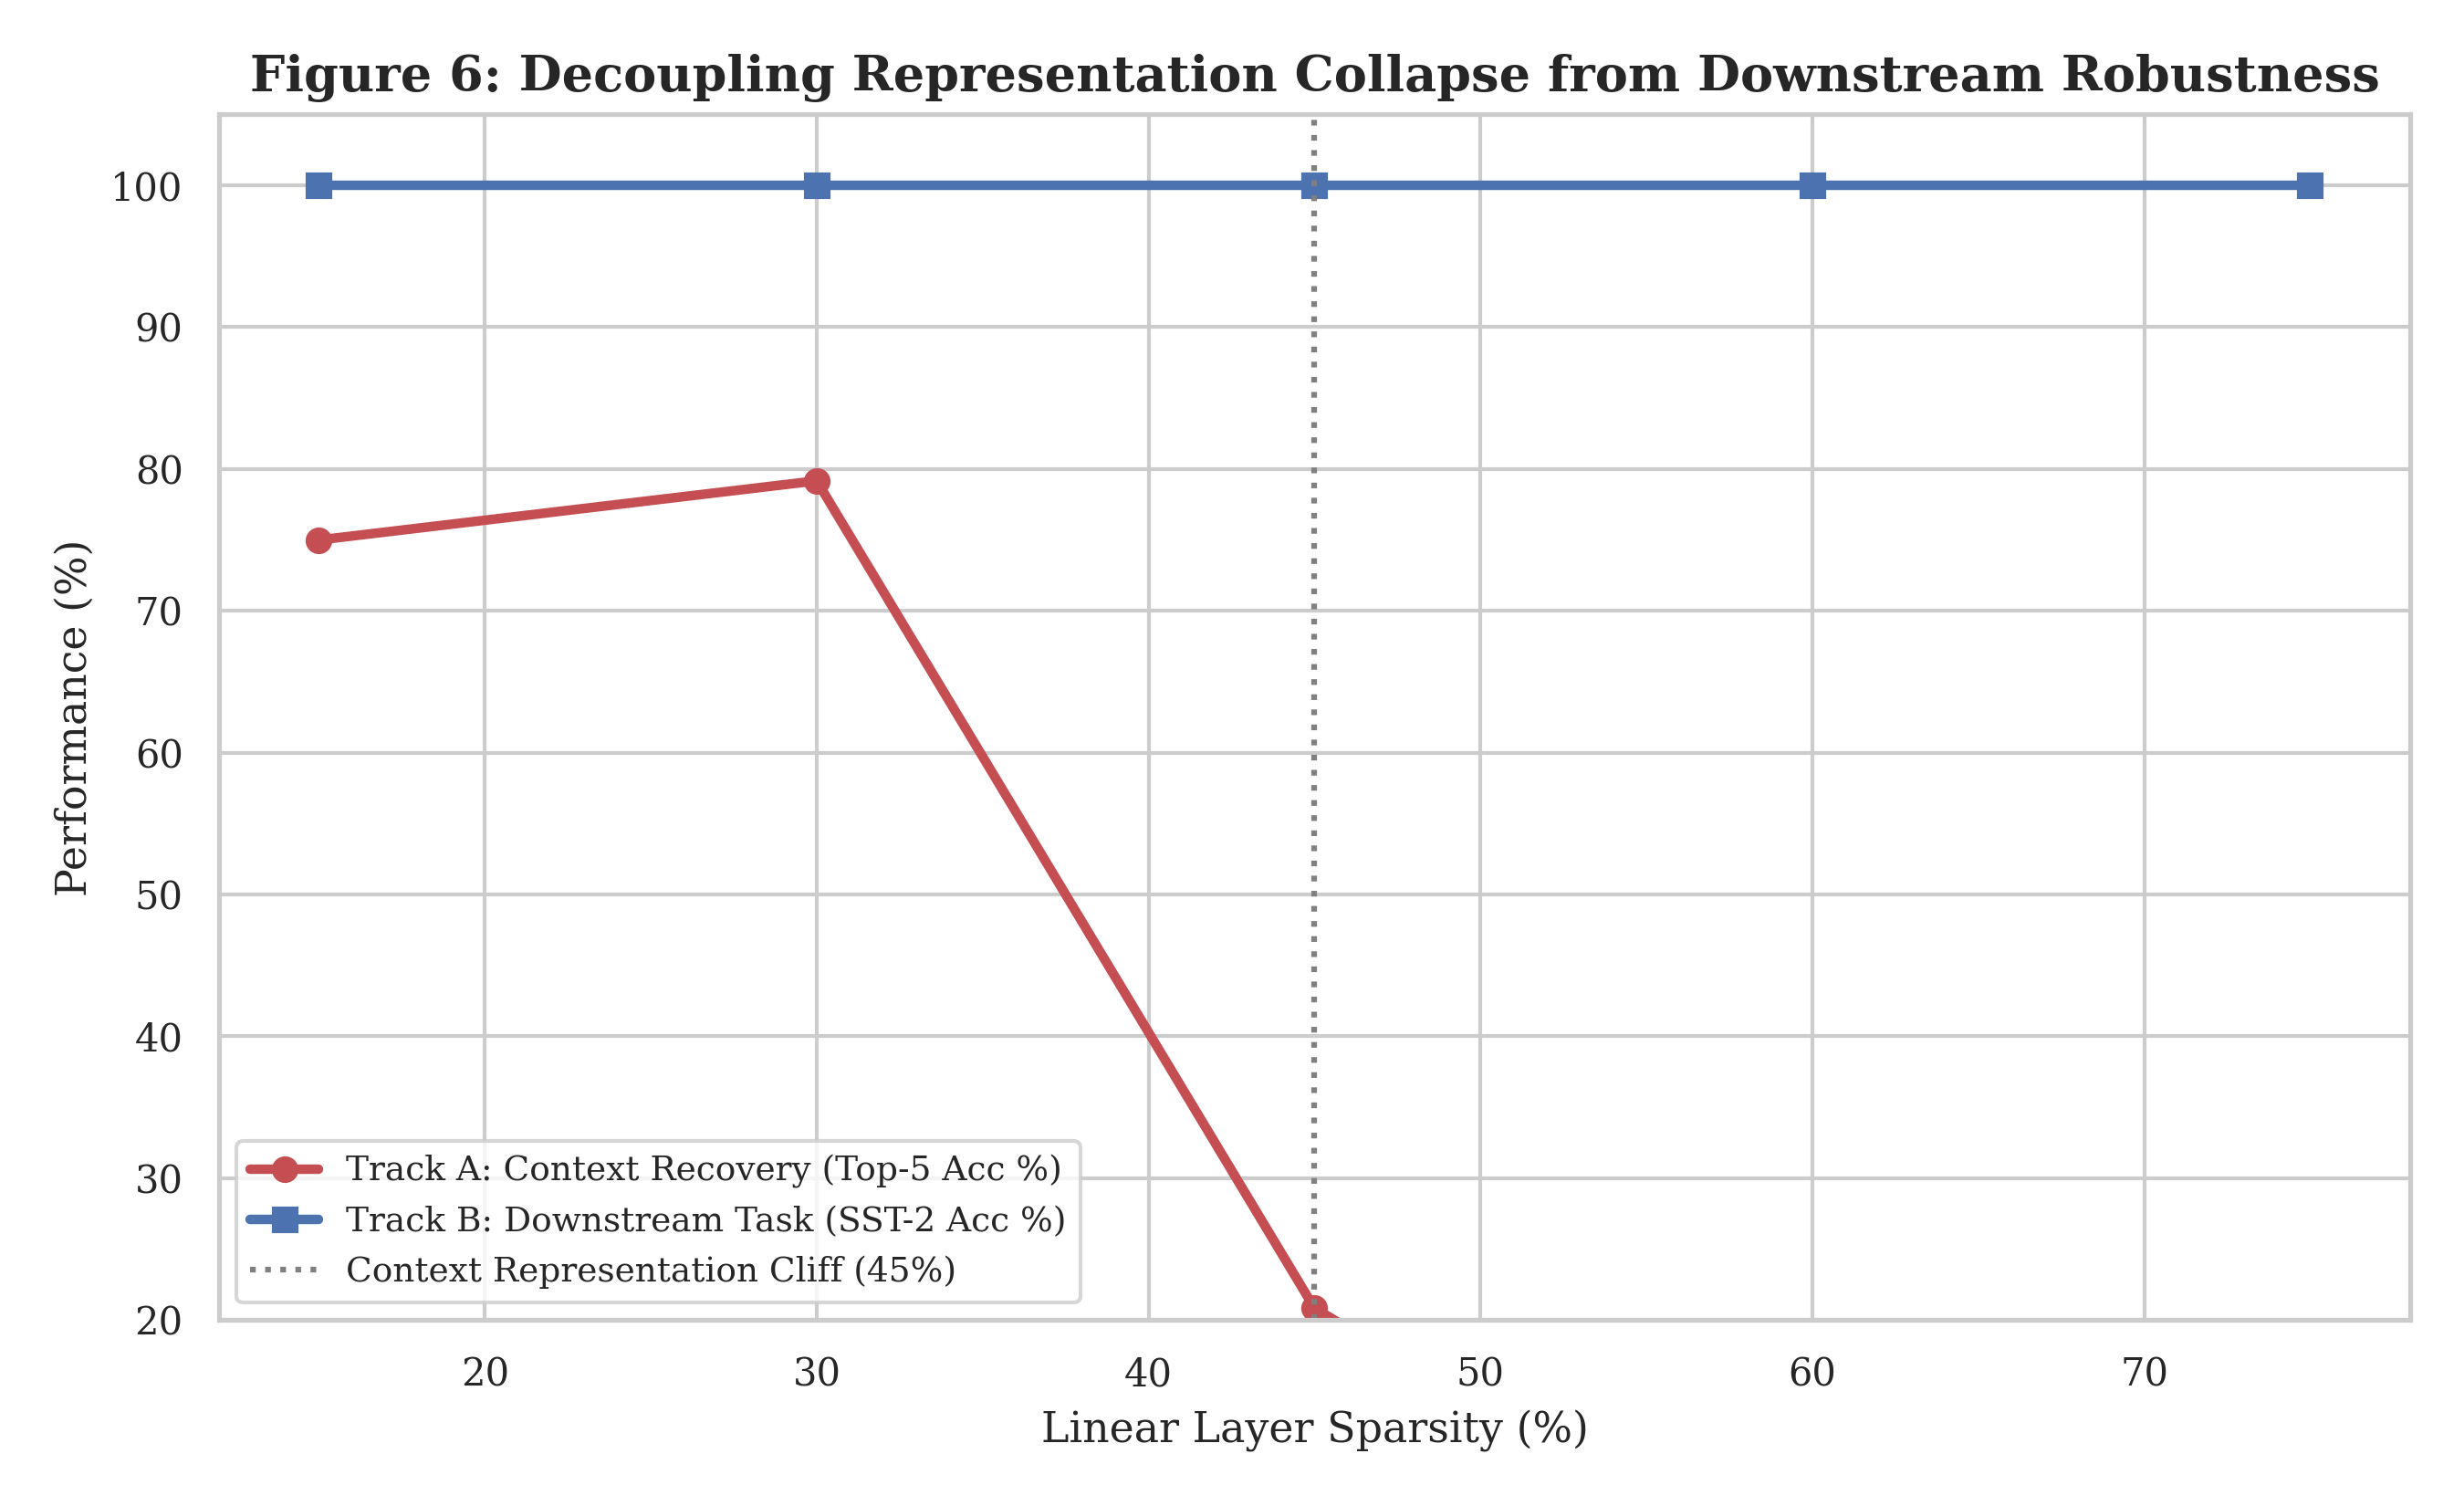

In [ ]:
# ============================================================
# Step 6: Render Publication-Quality Figures (300 DPI)
# ============================================================

from IPython.display import Image, display

figures = [
    "results/figures/fig1_context_accuracy_vs_sparsity.png",
    "results/figures/fig2_embedding_drift.png",
    "results/figures/fig3_pareto_frontier.png",
    "results/figures/fig4_layer_sensitivity_heatmap.png",
    "results/figures/fig5_distillation_recovery.png",
    "results/figures/fig6_decoupling_track_a_vs_track_b.png"
]

for fig_path in figures:
    if os.path.exists(fig_path):
        print(f"\n{'='*70}\n{fig_path}\n{'='*70}")
        display(Image(filename=fig_path))



In [ ]:
# ============================================================
# Step 7: Launch Interactive Real-Time Gradio Lab
# ============================================================
# Launches the interactive testing harness with 3 tabs:
# Tab 1: Track A Fill-Mask Context Predictor
# Tab 2: Track B Downstream SST-2 Sentiment Classifier
# Tab 3: Track A Semantic Vector Alignment & Drift Calculator

# We can launch directly from our modular dashboard module:
import dashboard

dashboard.demo.launch(share=True, debug=False)



Initializing models for Gradio Research Dashboard...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/content/dashboard.py:168: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="SLM Compression & Representation Research Lab", theme=custom_theme) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://96578a117817aeb21a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
